# Day 23 Sensor Fusion — chạy trên Kaggle (gồm BONUS)

**Trước khi chạy:** Settings → **Accelerator: GPU**, **Internet: On**; Add Input dataset `sensor-fusion` (đã có Waymo + weights).
Chạy lần lượt từng cell (hoặc *Run All*). Kết quả cuối cùng nằm ở tab **Output**: `submission.zip` (và thư mục `submission/`).

Notebook này **tự chứa** code Part E–H và script bonus `student/bonus/run_bonus.py` (cell 2 ghi vào bản clone), nên không cần push code lên GitHub trước.
Cell 7b chạy bonus (lệch calibration + trực quan hoá). Kết quả cuối: `submission.zip` gồm artifacts, `SUBMISSION.md` (đã có mục Bonus) và thư mục `student/bonus/`.

In [1]:
# Cell 1 — clone repo vào /tmp (không nằm trong Output) và cài thư viện
import os, subprocess, sys
REPO_URL = "https://github.com/Jikay-070203/K4-L2L3-DAY23-NguyenThanhHoa-2A202602559-SensorFusion.git"
REPO = "/tmp/repo"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", REPO_URL, REPO], check=True)
print(os.listdir(REPO))

Cloning into '/tmp/repo'...


['.env.example', 'submission', 'student', '2A202602559-NguyenThanhHoa.ipynb', 'data', 'RUBRIC.md', '.dockerignore', '.git', 'SUBMISSION.md', '.gitignore', 'NOTICE.md', 'docker', 'README.md', 'RULES.md', 'tools', '.github', 'CHECKPOINTS.md', 'docs', 'platform', 'environment.yml']


In [2]:
!pip install -q shapely easydict "protobuf>=6.33.5,<7" pyyaml tqdm scipy pytest

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 5.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.


In [3]:
# Cell 2 — ghi code Part E-H (đã viết + đã pass 128 test cục bộ) vào repo
import base64, pathlib
EMBEDDED = {"kalman.py": "IiIiRXh0ZW5kZWQgS2FsbWFuIGZpbHRlciBoZWxwZXJzIGZvciA2RCBjb25zdGFudC12ZWxvY2l0eSBtb3Rpb24uDQoNClBhcnQgRSBzdXBwbGllcyBwcmVkaWN0aW9uIGFuZCBjb3JyZWN0aW9uIGZvciBkb2NzL0hVT05HX0RBTl9LWV9USFVBVC5tZCDCpzIuDQpSZWFkIHRoZSBzaGFyZWQgdGltZSBzdGVwIGFuZCBwcm9jZXNzLW5vaXNlIHNldHRpbmdzIHdpdGggZ2V0X3RyYWNraW5nX3BhcmFtcygpLg0KIiIiDQoNCmZyb20gX19mdXR1cmVfXyBpbXBvcnQgYW5ub3RhdGlvbnMNCg0KZnJvbSB0eXBpbmcgaW1wb3J0IEFueQ0KZnJvbSB0eXBpbmcgaW1wb3J0IE9wdGlvbmFsDQoNCmltcG9ydCBudW1weSBhcyBucA0KDQpmcm9tIGZ1c2lvbl9sYWIud29ya3NwYWNlX3N1cHBvcnQgaW1wb3J0IGdldF90cmFja2luZ19wYXJhbXMNCg0KTWF0cml4ID0gbnAubWF0cml4IHwgbnAubmRhcnJheQ0KDQpwYXJhbXMgPSBnZXRfdHJhY2tpbmdfcGFyYW1zKCkNCg0KDQpkZWYgYnVpbGRfRihkdDogT3B0aW9uYWxbZmxvYXRdID0gTm9uZSkgLT4gTWF0cml4Og0KICAgICIiIkJ1aWxkIHRoZSBjb25zdGFudC12ZWxvY2l0eSBzdGF0ZSB0cmFuc2l0aW9uIG1hdHJpeCBGLg0KDQogICAgQXJnczoNCiAgICAgICAgZHQ6IFRpbWUgc3RlcCBpbiBzZWNvbmRzOyBkZWZhdWx0IGZyb20gdHJhY2tpbmcgcGFyYW1zLg0KDQogICAgUmV0dXJuczoNCiAgICAgICAgNng2IHN0YXRlIHRyYW5zaXRpb24gbWF0cml4IGFzIGBgbnAubWF0cml4YGAuDQogICAgIiIiDQogICAgaWYgZHQgaXMgTm9uZToNCiAgICAgICAgZHQgPSBwYXJhbXMuZHQNCiAgICBGID0gbnAuYXNtYXRyaXgobnAuZXllKHBhcmFtcy5kaW1fc3RhdGUpKQ0KICAgIEZbMCwgM10gPSBGWzEsIDRdID0gRlsyLCA1XSA9IGR0ICAjIHBvc2l0aW9uICs9IHZlbG9jaXR5ICogZHQNCiAgICByZXR1cm4gRg0KDQoNCmRlZiBidWlsZF9RKGR0OiBPcHRpb25hbFtmbG9hdF0gPSBOb25lLCBxOiBPcHRpb25hbFtmbG9hdF0gPSBOb25lKSAtPiBNYXRyaXg6DQogICAgIiIiQnVpbGQgdGhlIHByb2Nlc3Mgbm9pc2UgY292YXJpYW5jZSBtYXRyaXggUS4NCg0KICAgIEFyZ3M6DQogICAgICAgIGR0OiBUaW1lIHN0ZXA7IGRlZmF1bHQgZnJvbSB0cmFja2luZyBwYXJhbXMuDQogICAgICAgIHE6IFByb2Nlc3Mgbm9pc2Ugc2NhbGU7IGRlZmF1bHQgZnJvbSB0cmFja2luZyBwYXJhbXMuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICA2eDYgcHJvY2VzcyBub2lzZSBtYXRyaXguDQogICAgIiIiDQogICAgaWYgZHQgaXMgTm9uZToNCiAgICAgICAgZHQgPSBwYXJhbXMuZHQNCiAgICBpZiBxIGlzIE5vbmU6DQogICAgICAgIHEgPSBwYXJhbXMucQ0KICAgIHJldHVybiBucC5hc21hdHJpeChucC5kaWFnKFtkdCAqIHFdICogcGFyYW1zLmRpbV9zdGF0ZSkpDQoNCg0KZGVmIGVrZl9wcmVkaWN0KA0KICAgIHg6IE1hdHJpeCwNCiAgICBQOiBNYXRyaXgsDQogICAgRjogT3B0aW9uYWxbTWF0cml4XSA9IE5vbmUsDQogICAgUTogT3B0aW9uYWxbTWF0cml4XSA9IE5vbmUsDQopIC0+IHR1cGxlW01hdHJpeCwgTWF0cml4XToNCiAgICAiIiJQcmVkaWN0IHN0YXRlIGFuZCBjb3ZhcmlhbmNlIG9uZSB0aW1lIHN0ZXAgZm9yd2FyZC4NCg0KICAgIEFyZ3M6DQogICAgICAgIHg6IFN0YXRlIHZlY3RvciAoNngxKS4NCiAgICAgICAgUDogU3RhdGUgY292YXJpYW5jZSAoNng2KS4NCiAgICAgICAgRjogT3B0aW9uYWwgdHJhbnNpdGlvbiBtYXRyaXg7IGJ1aWxkIHZpYSBgYGJ1aWxkX0ZgYCBpZiBOb25lLg0KICAgICAgICBROiBPcHRpb25hbCBwcm9jZXNzIG5vaXNlOyBidWlsZCB2aWEgYGBidWlsZF9RYGAgaWYgTm9uZS4NCg0KICAgIFJldHVybnM6DQogICAgICAgIFR1cGxlIGBgKHhfcHJlZCwgUF9wcmVkKWBgLg0KICAgICIiIg0KICAgIGlmIEYgaXMgTm9uZToNCiAgICAgICAgRiA9IGJ1aWxkX0YoKQ0KICAgIGlmIFEgaXMgTm9uZToNCiAgICAgICAgUSA9IGJ1aWxkX1EoKQ0KICAgIEYsIFEgPSBucC5hc21hdHJpeChGKSwgbnAuYXNtYXRyaXgoUSkNCiAgICB4LCBQID0gbnAuYXNtYXRyaXgoeCksIG5wLmFzbWF0cml4KFApDQogICAgcmV0dXJuIEYgQCB4LCBGIEAgUCBAIEYuVCArIFENCg0KDQpkZWYgaW5ub3ZhdGlvbih4OiBNYXRyaXgsIG1lYXM6IEFueSkgLT4gTWF0cml4Og0KICAgICIiIkNvbXB1dGUgdGhlIG1lYXN1cmVtZW50IHJlc2lkdWFsIChpbm5vdmF0aW9uKSBnYW1tYS4NCg0KICAgIEFyZ3M6DQogICAgICAgIHg6IFByZWRpY3RlZCBzdGF0ZS4NCiAgICAgICAgbWVhczogTWVhc3VyZW1lbnQgd2l0aCBgYHpgYCBhbmQgYGBzZW5zb3IuZ2V0X2h4KHgpYGAuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBJbm5vdmF0aW9uIHZlY3RvciBgYHogLSBoKHgpYGAuDQogICAgIiIiDQogICAgcmV0dXJuIG1lYXMueiAtIG1lYXMuc2Vuc29yLmdldF9oeCh4KQ0KDQoNCmRlZiBpbm5vdmF0aW9uX2NvdmFyaWFuY2UoUDogTWF0cml4LCBtZWFzOiBBbnksIEg6IE1hdHJpeCkgLT4gTWF0cml4Og0KICAgICIiIkNvbXB1dGUgdGhlIGlubm92YXRpb24gY292YXJpYW5jZSBTID0gSCBQIEgnICsgUi4NCg0KICAgIEFyZ3M6DQogICAgICAgIFA6IFN0YXRlIGNvdmFyaWFuY2UuDQogICAgICAgIG1lYXM6IE1lYXN1cmVtZW50IHdpdGggYGBSYGAuDQogICAgICAgIEg6IE1lYXN1cmVtZW50IEphY29iaWFuLg0KDQogICAgUmV0dXJuczoNCiAgICAgICAgSW5ub3ZhdGlvbiBjb3ZhcmlhbmNlIG1hdHJpeCBTLg0KICAgICIiIg0KICAgIEggPSBucC5hc21hdHJpeChIKQ0KICAgIHJldHVybiBIIEAgbnAuYXNtYXRyaXgoUCkgQCBILlQgKyBtZWFzLlINCg0KDQpkZWYgZWtmX3VwZGF0ZSh4OiBNYXRyaXgsIFA6IE1hdHJpeCwgbWVhczogQW55KSAtPiB0dXBsZVtNYXRyaXgsIE1hdHJpeF06DQogICAgIiIiQXBwbHkgYW4gRUtGIG1lYXN1cmVtZW50IHVwZGF0ZSBhbmQgcmV0dXJuIHVwZGF0ZWQgc3RhdGUgYW5kIGNvdmFyaWFuY2UuDQoNCiAgICBBcmdzOg0KICAgICAgICB4OiBQcmlvciBzdGF0ZS4NCiAgICAgICAgUDogUHJpb3IgY292YXJpYW5jZS4NCiAgICAgICAgbWVhczogQXNzb2NpYXRlZCBtZWFzdXJlbWVudC4NCg0KICAgIFJldHVybnM6DQogICAgICAgIFR1cGxlIGBgKHhfdXBkLCBQX3VwZClgYC4NCiAgICAiIiINCiAgICB4LCBQID0gbnAuYXNtYXRyaXgoeCksIG5wLmFzbWF0cml4KFApDQogICAgSCA9IG5wLmFzbWF0cml4KG1lYXMuc2Vuc29yLmdldF9IKHgpKQ0KICAgIGdhbW1hID0gaW5ub3ZhdGlvbih4LCBtZWFzKQ0KICAgIFMgPSBpbm5vdmF0aW9uX2NvdmFyaWFuY2UoUCwgbWVhcywgSCkNCiAgICBLID0gUCBAIEguVCBAIG5wLmxpbmFsZy5pbnYoUykNCiAgICBpZGVudGl0eSA9IG5wLmFzbWF0cml4KG5wLmV5ZShQLnNoYXBlWzBdKSkNCiAgICByZXR1cm4geCArIEsgQCBnYW1tYSwgKGlkZW50aXR5IC0gSyBAIEgpIEAgUA0K", "association.py": "IiIiTWVhc3VyZW1lbnQtdG8tdHJhY2sgYXNzb2NpYXRpb24gdmlhIE1haGFsYW5vYmlzIGdhdGluZyBhbmQgZ3JlZWR5IG1hdGNoaW5nLg0KDQpQYXJ0IEYgc3VwcGxpZXMgdGhlIGFzc29jaWF0aW9uIHN0YWdlIHNob3duIGluIGRvY3MvSFVPTkdfREFOX0tZX1RIVUFULm1kIMKnMi4NCkxvYWQgYGBrYWxtYW5gYCB3aXRoIGBgbG9hZF93b3Jrc3BhY2VfbW9kdWxlYGAgZm9yIGlubm92YXRpb24gaGVscGVycyBhbmQgdHJhY2tpbmcgcGFyYW1ldGVycw0KZm9yIHRoZSBjaGktc3F1YXJlIGdhdGUuDQoiIiINCg0KZnJvbSBfX2Z1dHVyZV9fIGltcG9ydCBhbm5vdGF0aW9ucw0KDQpmcm9tIHR5cGluZyBpbXBvcnQgQW55DQpmcm9tIHR5cGluZyBpbXBvcnQgU2VxdWVuY2UNCg0KaW1wb3J0IG51bXB5IGFzIG5wDQpmcm9tIHNjaXB5LnN0YXRzIGltcG9ydCBjaGkyDQoNCmZyb20gZnVzaW9uX2xhYi53b3Jrc3BhY2VfbG9hZGVyIGltcG9ydCBsb2FkX3dvcmtzcGFjZV9tb2R1bGUNCmZyb20gZnVzaW9uX2xhYi53b3Jrc3BhY2Vfc3VwcG9ydCBpbXBvcnQgZ2V0X3RyYWNraW5nX3BhcmFtcw0KDQprYWxtYW4gPSBsb2FkX3dvcmtzcGFjZV9tb2R1bGUoImthbG1hbiIpICAjIG5vdCBgaW1wb3J0IGthbG1hbmA6IGF2b2lkcyBhIHN0YWxlIG1vZHVsZQ0KcGFyYW1zID0gZ2V0X3RyYWNraW5nX3BhcmFtcygpDQoNCg0KZGVmIG1haGFsYW5vYmlzX2Rpc3RhbmNlKHRyYWNrOiBBbnksIG1lYXM6IEFueSkgLT4gZmxvYXQ6DQogICAgIiIiUmV0dXJuIHNxdWFyZWQgTWFoYWxhbm9iaXMgZGlzdGFuY2UgYmV0d2VlbiBhIHRyYWNrIGFuZCBhIG1lYXN1cmVtZW50Lg0KDQogICAgQXJnczoNCiAgICAgICAgdHJhY2s6IFRyYWNrIHdpdGggYGB4YGAsIGBgUGBgLg0KICAgICAgICBtZWFzOiBNZWFzdXJlbWVudCB3aXRoIGBgc2Vuc29yYGAuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBTY2FsYXIgc3F1YXJlZCBNYWhhbGFub2JpcyBkaXN0YW5jZS4NCiAgICAiIiINCiAgICBIID0gbWVhcy5zZW5zb3IuZ2V0X0godHJhY2sueCkNCiAgICBnYW1tYSA9IGthbG1hbi5pbm5vdmF0aW9uKHRyYWNrLngsIG1lYXMpDQogICAgUyA9IGthbG1hbi5pbm5vdmF0aW9uX2NvdmFyaWFuY2UodHJhY2suUCwgbWVhcywgSCkNCiAgICAjIC5pdGVtKCkgY29udmVydHMgdGhlIDF4MSByZXN1bHQ7IGZsb2F0KCkgb24gYSAyLUQgYXJyYXkgZmFpbHMgb24gTnVtUHkgPj0gMi4NCiAgICByZXR1cm4gZmxvYXQoKGdhbW1hLlQgQCBucC5saW5hbGcuaW52KFMpIEAgZ2FtbWEpLml0ZW0oKSkNCg0KDQpkZWYgY2hpMl9nYXRlKG1oZF9zcTogZmxvYXQsIHNlbnNvcjogQW55KSAtPiBib29sOg0KICAgICIiIlJldHVybiBUcnVlIGlmIHNxdWFyZWQgTWFoYWxhbm9iaXMgZGlzdGFuY2UgbGllcyBpbnNpZGUgdGhlIGNoaS1zcXVhcmUgZ2F0ZS4NCg0KICAgIEFyZ3M6DQogICAgICAgIG1oZF9zcTogU3F1YXJlZCBNYWhhbGFub2JpcyBkaXN0YW5jZS4NCiAgICAgICAgc2Vuc29yOiBTZW5zb3Igd2l0aCBgYGRpbV9tZWFzYGAuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBUcnVlIGlmIGluc2lkZSBnYXRlLg0KICAgICIiIg0KICAgIGxpbWl0ID0gY2hpMi5wcGYocGFyYW1zLmdhdGluZ190aHJlc2hvbGQsIHNlbnNvci5kaW1fbWVhcykNCiAgICByZXR1cm4gYm9vbChtaGRfc3EgPCBsaW1pdCkNCg0KDQpkZWYgYXNzb2NpYXRpb25fY29zdF9tYXRyaXgoDQogICAgdHJhY2tfbGlzdDogU2VxdWVuY2VbQW55XSwgbWVhc19saXN0OiBTZXF1ZW5jZVtBbnldDQopIC0+IG5wLm1hdHJpeDoNCiAgICAiIiJCdWlsZCBnYXRlZCBjb3N0cywgY2hlY2tpbmcgZWFjaCBzZW5zb3IncyB2aXNpYmlsaXR5IGJlZm9yZSBwcm9qZWN0aW9uLg0KDQogICAgQXJnczoNCiAgICAgICAgdHJhY2tfbGlzdDogQWN0aXZlIHRyYWNrcy4NCiAgICAgICAgbWVhc19saXN0OiBNZWFzdXJlbWVudHMgZm9yIHRoaXMgc2Vuc29yIHBhc3MuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBDb3N0IG1hdHJpeDsgYGBucC5pbmZgYCBmb3IgaW52aXNpYmxlIHRyYWNrcyBvciByZWplY3RlZCBjaGktc3F1YXJlIGdhdGVzLg0KICAgICAgICBJbnZpc2libGUgcGFpcnMgbXVzdCBuZXZlciBjYWxsIHRoZSBNYWhhbGFub2Jpcy9wcm9qZWN0aW9uIGhlbHBlcnMuDQogICAgIiIiDQogICAgY29zdHMgPSBucC5mdWxsKChsZW4odHJhY2tfbGlzdCksIGxlbihtZWFzX2xpc3QpKSwgbnAuaW5mKQ0KICAgIGZvciBpLCB0cmFjayBpbiBlbnVtZXJhdGUodHJhY2tfbGlzdCk6DQogICAgICAgIGZvciBqLCBtZWFzIGluIGVudW1lcmF0ZShtZWFzX2xpc3QpOg0KICAgICAgICAgICAgIyBWaXNpYmlsaXR5IGZpcnN0OiBhbiBpbnZpc2libGUgcGFpciBtdXN0IG5ldmVyIHJlYWNoIHByb2plY3Rpb24vTUhELg0KICAgICAgICAgICAgaWYgbm90IG1lYXMuc2Vuc29yLmluX2Zvdih0cmFjay54KToNCiAgICAgICAgICAgICAgICBjb250aW51ZQ0KICAgICAgICAgICAgbWhkX3NxID0gbWFoYWxhbm9iaXNfZGlzdGFuY2UodHJhY2ssIG1lYXMpDQogICAgICAgICAgICBpZiBjaGkyX2dhdGUobWhkX3NxLCBtZWFzLnNlbnNvcik6DQogICAgICAgICAgICAgICAgY29zdHNbaSwgal0gPSBtaGRfc3ENCiAgICByZXR1cm4gbnAuYXNtYXRyaXgoY29zdHMpDQoNCg0KZGVmIHBpY2tfbmV4dF9wYWlyKA0KICAgIGFzc29jaWF0aW9uX21hdHJpeDogbnAubWF0cml4LA0KICAgIHVuYXNzaWduZWRfdHJhY2tzOiBTZXF1ZW5jZVtBbnldLA0KICAgIHVuYXNzaWduZWRfbWVhczogU2VxdWVuY2VbQW55XSwNCikgLT4gdHVwbGVbQW55LCBBbnksIG5wLm1hdHJpeCwgbGlzdFtBbnldLCBsaXN0W0FueV1dOg0KICAgICIiIlBpY2sgdGhlIG1pbmltdW0tY29zdCB0cmFjay9tZWFzdXJlbWVudCBwYWlyIGFuZCBzaHJpbmsgdGhlIGFzc29jaWF0aW9uIHByb2JsZW0uDQoNCiAgICBBcmdzOg0KICAgICAgICBhc3NvY2lhdGlvbl9tYXRyaXg6IEN1cnJlbnQgY29zdCBtYXRyaXguDQogICAgICAgIHVuYXNzaWduZWRfdHJhY2tzOiBUcmFjayBvYmplY3RzIHN0aWxsIGZyZWUuDQogICAgICAgIHVuYXNzaWduZWRfbWVhczogTWVhc3VyZW1lbnQgb2JqZWN0cyBzdGlsbCBmcmVlLg0KDQogICAgUmV0dXJuczoNCiAgICAgICAgVHVwbGUgKHRyYWNrLCBtZWFzLCBuZXdfbWF0cml4LCByZW1haW5pbmdfdHJhY2tzLCByZW1haW5pbmdfbWVhcykuDQogICAgICAgIElmIG5vIGZpbml0ZSBwYWlyIGV4aXN0cywgcmV0dXJuIG5wLm5hbiBmb3IgdHJhY2sgYW5kIG1lYXMgYW5kIHJldGFpbiBib3RoIGxpc3RzLg0KICAgICIiIg0KICAgIG1hdHJpeCA9IG5wLmFzYXJyYXkoYXNzb2NpYXRpb25fbWF0cml4LCBkdHlwZT1mbG9hdCkNCiAgICB0cmFja3MsIG1lYXN1cmVtZW50cyA9IGxpc3QodW5hc3NpZ25lZF90cmFja3MpLCBsaXN0KHVuYXNzaWduZWRfbWVhcykNCiAgICBpZiBtYXRyaXguc2l6ZSA9PSAwIG9yIG5vdCBucC5pc2Zpbml0ZShtYXRyaXgpLmFueSgpOg0KICAgICAgICByZXR1cm4gbnAubmFuLCBucC5uYW4sIG5wLmFzbWF0cml4KG1hdHJpeCksIHRyYWNrcywgbWVhc3VyZW1lbnRzDQogICAgbWFza2VkID0gbnAud2hlcmUobnAuaXNmaW5pdGUobWF0cml4KSwgbWF0cml4LCBucC5pbmYpDQogICAgaSwgaiA9IG5wLnVucmF2ZWxfaW5kZXgobnAuYXJnbWluKG1hc2tlZCksIG1hc2tlZC5zaGFwZSkNCiAgICB0cmFjaywgbWVhcyA9IHRyYWNrcy5wb3AoaSksIG1lYXN1cmVtZW50cy5wb3AoaikNCiAgICByZW1haW5pbmcgPSBucC5kZWxldGUobnAuZGVsZXRlKG1hdHJpeCwgaSwgYXhpcz0wKSwgaiwgYXhpcz0xKQ0KICAgIHJldHVybiB0cmFjaywgbWVhcywgbnAuYXNtYXRyaXgocmVtYWluaW5nKSwgdHJhY2tzLCBtZWFzdXJlbWVudHMNCg0KDQpkZWYgYXNzb2NpYXRlX2FuZF91cGRhdGUoDQogICAgbWFuYWdlcjogQW55LA0KICAgIG1lYXNfbGlzdDogU2VxdWVuY2VbQW55XSwNCiAgICBmaWx0ZXJfb2JqOiBBbnksDQogICAgc2Vuc29yOiBBbnksDQopIC0+IE5vbmU6DQogICAgIiIiR3JlZWR5IGFzc29jaWF0aW9uIGxvb3Agd2l0aCBFS0YgdXBkYXRlcyBhbmQgdHJhY2sgbWFuYWdlbWVudC4NCg0KICAgIEFyZ3M6DQogICAgICAgIG1hbmFnZXI6IFRyYWNrIG1hbmFnZXIgKGBgdHJhY2tfbGlzdGBgLCBgYG1hbmFnZV90cmFja3NgYCwgLi4uKS4NCiAgICAgICAgbWVhc19saXN0OiBMaWRhciBvciBjYW1lcmEgbWVhc3VyZW1lbnRzIGZvciB0aGlzIGZyYW1lIHBhc3MuDQogICAgICAgIGZpbHRlcl9vYmo6IEZpbHRlciB3aXRoIGBgcHJlZGljdGBgIC8gYGB1cGRhdGVgYC4NCiAgICAgICAgc2Vuc29yOiBFeHBsaWNpdCBsaWRhci9jYW1lcmEgcGFzcyBzZW5zb3IsIGluY2x1ZGluZyBlbXB0eSBtZWFzdXJlbWVudCBmcmFtZXMuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBOb25lOyB1cGRhdGVzIHRyYWNrcyBpbiBwbGFjZSBhbmQgYWx3YXlzIGZpbmlzaGVzIHRoZSBsaWZlY3ljbGUgcGFzcy4NCiAgICAgICAgVmlzaWJpbGl0eSBpcyBoYW5kbGVkIGluIHRoZSBjb3N0IG1hdHJpeCwgYmVmb3JlIHBhaXIgcmVtb3ZhbC4gQ2FtZXJhDQogICAgICAgIHVwZGF0ZXMgcmVmaW5lIHN0YXRlIG9ubHk7IGxpZGFyIGhpdHMgYWxvbmUgaW5jcmVhc2UgZXhpc3RlbmNlIHNjb3Jlcy4NCiAgICAiIiINCiAgICB1bmFzc2lnbmVkX3RyYWNrcyA9IGxpc3QobWFuYWdlci50cmFja19saXN0KQ0KICAgIHVuYXNzaWduZWRfbWVhcyA9IGxpc3QobWVhc19saXN0KQ0KICAgIGNvc3RzID0gYXNzb2NpYXRpb25fY29zdF9tYXRyaXgodW5hc3NpZ25lZF90cmFja3MsIHVuYXNzaWduZWRfbWVhcykNCiAgICB3aGlsZSBjb3N0cy5zaXplID4gMDoNCiAgICAgICAgdHJhY2ssIG1lYXMsIGNvc3RzLCB1bmFzc2lnbmVkX3RyYWNrcywgdW5hc3NpZ25lZF9tZWFzID0gcGlja19uZXh0X3BhaXIoDQogICAgICAgICAgICBjb3N0cywgdW5hc3NpZ25lZF90cmFja3MsIHVuYXNzaWduZWRfbWVhcw0KICAgICAgICApDQogICAgICAgIGlmIGlzaW5zdGFuY2UodHJhY2ssIGZsb2F0KSBhbmQgbnAuaXNuYW4odHJhY2spOg0KICAgICAgICAgICAgYnJlYWsgICMgbm8gZmluaXRlICh2aXNpYmxlIGFuZCBnYXRlZCkgcGFpciBpcyBsZWZ0DQogICAgICAgIGZpbHRlcl9vYmoudXBkYXRlKHRyYWNrLCBtZWFzKQ0KICAgICAgICBtYW5hZ2VyLmhhbmRsZV91cGRhdGVkX3RyYWNrKHRyYWNrLCBzZW5zb3IpDQogICAgIyBBbHdheXMgZmluaXNoIHRoZSBwYXNzLCBldmVuIHdpdGggbm8gbWVhc3VyZW1lbnRzIChsaWRhciBtaXNzZXMvYmlydGhzKS4NCiAgICBtYW5hZ2VyLm1hbmFnZV90cmFja3ModW5hc3NpZ25lZF90cmFja3MsIHVuYXNzaWduZWRfbWVhcywgc2Vuc29yKQ0K", "camera_fusion.py": "IiIiQ2FtZXJhIGZpZWxkLW9mLXZpZXcgY2hlY2tzIGFuZCBwaW5ob2xlIG1lYXN1cmVtZW50IG1vZGVsaW5nLg0KDQpQYXJ0IEcgc3VwcGxpZXMgdmlzaWJpbGl0eSwgcHJvamVjdGlvbiwgYW5kIHBpeGVsIGNvdmFyaWFuY2UgKGRvY3MvSFVPTkdfREFOX0tZX1RIVUFULm1kIMKnMikuDQpUaGUgcGxhdGZvcm0gZGlmZmVyZW50aWF0ZXMgcHJvamVjdGlvbiB1c2luZyBhIGNoYWluLXJ1bGUgSmFjb2JpYW4uDQoiIiINCg0KZnJvbSBfX2Z1dHVyZV9fIGltcG9ydCBhbm5vdGF0aW9ucw0KDQpmcm9tIHR5cGluZyBpbXBvcnQgQW55DQpmcm9tIHR5cGluZyBpbXBvcnQgU2VxdWVuY2UNCg0KaW1wb3J0IG51bXB5IGFzIG5wDQoNCmZyb20gZnVzaW9uX2xhYi53b3Jrc3BhY2Vfc3VwcG9ydCBpbXBvcnQgZ2V0X3RyYWNraW5nX3BhcmFtcw0KDQpNYXRyaXggPSBucC5tYXRyaXggfCBucC5uZGFycmF5DQoNCk1JTl9ERVBUSCA9IDFlLTYNCg0KDQpkZWYgX3Bvc2l0aW9uX2luX3NlbnNvcih4OiBNYXRyaXgsIHNlbnNvcjogQW55KSAtPiBucC5uZGFycmF5Og0KICAgICIiIlJldHVybiB0aGUgKHgsIHksIHopIHBvc2l0aW9uIG9mIHN0YXRlIHggaW4gdGhlIHNlbnNvciBmcmFtZSwgcF9zID0gUiBwICsgdC4iIiINCiAgICBwb3NpdGlvbiA9IG5wLmFzYXJyYXkoeCwgZHR5cGU9ZmxvYXQpLnJlc2hhcGUoLTEpWzozXQ0KICAgIHRyYW5zZm9ybSA9IG5wLmFzYXJyYXkoc2Vuc29yLnZlaF90b19zZW5zLCBkdHlwZT1mbG9hdCkNCiAgICByZXR1cm4gdHJhbnNmb3JtWzozLCA6M10gQCBwb3NpdGlvbiArIHRyYW5zZm9ybVs6MywgM10NCg0KDQpkZWYgaXNfaW5fZmllbGRfb2Zfdmlldyh4OiBNYXRyaXgsIHNlbnNvcjogQW55KSAtPiBib29sOg0KICAgICIiIlJldHVybiBUcnVlIGlmIHN0YXRlIHggaXMgdmlzaWJsZSB3aXRoaW4gdGhlIHNlbnNvciBob3Jpem9udGFsIGZpZWxkIG9mIHZpZXcuDQoNCiAgICBBcmdzOg0KICAgICAgICB4OiBTdGF0ZSB2ZWN0b3IgKDZ4MSkgd2l0aCBwb3NpdGlvbiBpbiB2ZWhpY2xlIGZyYW1lLg0KICAgICAgICBzZW5zb3I6IExpZGFyIG9yIGNhbWVyYSBhZGFwdGVyIHdpdGggYGB2ZWhfdG9fc2Vuc2BgIGFuZCBgYGZvdmBgDQogICAgICAgICAgICAocmFkaWFucykuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBUcnVlIGlmIHNlbnNvciBjb29yZGluYXRlcyBhcmUgZmluaXRlIGFuZCB0aGUgaG9yaXpvbnRhbCBhbmdsZSBpcyB3aXRoaW4NCiAgICAgICAgYGBzZW5zb3IuZm92YGAuIEEgY2FtZXJhIGFkZGl0aW9uYWxseSByZXF1aXJlcyBkZXB0aCA+IDFlLTYuDQogICAgIiIiDQogICAgcF9zID0gX3Bvc2l0aW9uX2luX3NlbnNvcih4LCBzZW5zb3IpDQogICAgaWYgbm90IG5wLmlzZmluaXRlKHBfcykuYWxsKCk6DQogICAgICAgIHJldHVybiBGYWxzZQ0KICAgIGlmIGdldGF0dHIoc2Vuc29yLCAibmFtZSIsIE5vbmUpID09ICJjYW1lcmEiIGFuZCBwX3NbMF0gPD0gTUlOX0RFUFRIOg0KICAgICAgICByZXR1cm4gRmFsc2UNCiAgICBhbHBoYSA9IG5wLmFyY3RhbjIocF9zWzFdLCBwX3NbMF0pDQogICAgbG93LCBoaWdoID0gbWluKHNlbnNvci5mb3YpLCBtYXgoc2Vuc29yLmZvdikNCiAgICByZXR1cm4gYm9vbChsb3cgPD0gYWxwaGEgPD0gaGlnaCkNCg0KDQpkZWYgY2FtZXJhX21lYXN1cmVtZW50X3ByZWRpY3Rpb24oeDogTWF0cml4LCBzZW5zb3I6IEFueSkgLT4gTWF0cml4Og0KICAgICIiIlByZWRpY3QgaW1hZ2UtcGxhbmUgbWVhc3VyZW1lbnQgaCh4KSB1c2luZyB0aGUgcGluaG9sZSBjYW1lcmEgbW9kZWwuDQoNCiAgICBBcmdzOg0KICAgICAgICB4OiBTdGF0ZSB2ZWN0b3IuDQogICAgICAgIHNlbnNvcjogQ2FtZXJhIHdpdGggaW50cmluc2ljcyBgYGZfaSwgZl9qLCBjX2ksIGNfamBgLg0KDQogICAgUmV0dXJuczoNCiAgICAgICAgMngxIHByZWRpY3RlZCBwaXhlbCBjb29yZGluYXRlcyBhcyBgYG5wLm1hdHJpeGBgLg0KDQogICAgUmFpc2VzOg0KICAgICAgICBWYWx1ZUVycm9yOiBXaXRoIGNvb3JkaW5hdGUgY29udGV4dCBpZiBzZW5zb3IgY29vcmRpbmF0ZXMgYXJlIG5vbmZpbml0ZQ0KICAgICAgICAgICAgb3IgZGVwdGggaXMgYXQgbW9zdCAxZS02Lg0KICAgICIiIg0KICAgIHBfcyA9IF9wb3NpdGlvbl9pbl9zZW5zb3IoeCwgc2Vuc29yKQ0KICAgIGlmIG5vdCBucC5pc2Zpbml0ZShwX3MpLmFsbCgpIG9yIHBfc1swXSA8PSBNSU5fREVQVEg6DQogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoDQogICAgICAgICAgICAiQ2FtZXJhIHByb2plY3Rpb24gbmVlZHMgZmluaXRlIGNvb3JkaW5hdGVzIGFuZCBwb3NpdGl2ZSBkZXB0aCAiDQogICAgICAgICAgICBmIj4ge01JTl9ERVBUSDpnfTsgc2Vuc29yIHBvc2l0aW9uPXtwX3MudG9saXN0KCl9Ig0KICAgICAgICApDQogICAgdSA9IHNlbnNvci5jX2kgLSBzZW5zb3IuZl9pICogcF9zWzFdIC8gcF9zWzBdDQogICAgdiA9IHNlbnNvci5jX2ogLSBzZW5zb3IuZl9qICogcF9zWzJdIC8gcF9zWzBdDQogICAgcmV0dXJuIG5wLmFzbWF0cml4KFtbdV0sIFt2XV0sIGR0eXBlPWZsb2F0KQ0KDQoNCmRlZiBidWlsZF9jYW1lcmFfbWVhc3VyZW1lbnQoejogU2VxdWVuY2VbZmxvYXRdLCBzZW5zb3I6IEFueSkgLT4gZGljdFtzdHIsIEFueV06DQogICAgIiIiQnVpbGQgY2FtZXJhIG1lYXN1cmVtZW50IHZlY3RvciB6IGFuZCBjb3ZhcmlhbmNlIFIgZnJvbSBwaXhlbCBjb29yZGluYXRlcy4NCg0KICAgIEFyZ3M6DQogICAgICAgIHo6IFNlcXVlbmNlIGBgW3UsIHZdYGAgcGl4ZWwgY29vcmRpbmF0ZXMuDQogICAgICAgIHNlbnNvcjogQ2FtZXJhIHNlbnNvciBvYmplY3QuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBEaWN0IHdpdGgga2V5cyBgYHpgYCwgYGBSYGAsIGBgc2Vuc29yYGAuDQogICAgIiIiDQogICAgcGFyYW1zID0gZ2V0X3RyYWNraW5nX3BhcmFtcygpDQogICAgel9tYXQgPSBucC5hc21hdHJpeChucC5hc2FycmF5KHosIGR0eXBlPWZsb2F0KS5yZXNoYXBlKC0xKVs6Ml0pLlQNCiAgICBSID0gbnAuYXNtYXRyaXgobnAuZGlhZyhbcGFyYW1zLnNpZ21hX2NhbV9pKioyLCBwYXJhbXMuc2lnbWFfY2FtX2oqKjJdKSkNCiAgICByZXR1cm4geyJ6Ijogel9tYXQsICJSIjogUiwgInNlbnNvciI6IHNlbnNvcn0NCg==", "track_management.py": "IiIiVHJhY2sgaW5pdGlhbGl6YXRpb24sIHNjb3JpbmcsIGFuZCBkZWxldGlvbiBoZWxwZXJzLg0KDQpQYXJ0IEggc3VwcGxpZXMgbGlkYXItZHJpdmVuIGV4aXN0ZW5jZSBkZWNpc2lvbnMgKGRvY3MvSFVPTkdfREFOX0tZX1RIVUFULm1kIMKnMikuDQpVc2UgdHJhY2tpbmcgcGFyYW1ldGVycyBmb3IgdGhlIHNjb3JlIHdpbmRvdywgdGhyZXNob2xkcywgYW5kIGNvdmFyaWFuY2UgbGltaXQuDQoiIiINCg0KZnJvbSBfX2Z1dHVyZV9fIGltcG9ydCBhbm5vdGF0aW9ucw0KDQpmcm9tIHR5cGluZyBpbXBvcnQgQW55DQoNCmltcG9ydCBudW1weSBhcyBucA0KDQpmcm9tIGZ1c2lvbl9sYWIud29ya3NwYWNlX3N1cHBvcnQgaW1wb3J0IGdldF90cmFja2luZ19wYXJhbXMNCg0KcGFyYW1zID0gZ2V0X3RyYWNraW5nX3BhcmFtcygpDQoNCg0KZGVmIGluaXRfdHJhY2tfc3RhdGVfZnJvbV9tZWFzKG1lYXM6IEFueSkgLT4gZGljdFtzdHIsIEFueV06DQogICAgIiIiSW5pdGlhbGl6ZSB0cmFjayBzdGF0ZSwgY292YXJpYW5jZSwgbGlmZWN5Y2xlIHN0YXRlLCBhbmQgc2NvcmUgZnJvbSBhIG1lYXN1cmVtZW50Lg0KDQogICAgQXJnczoNCiAgICAgICAgbWVhczogTGlkYXIgbWVhc3VyZW1lbnQgd2l0aCBgYHpgYCwgYGBSYGAsIGBgc2Vuc29yYGAuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBEaWN0IHdpdGgga2V5cyBgYHhgYCwgYGBQYGAsIGBgc3RhdGVgYCwgYGBzY29yZWBgIChtYXRyaWNlcyBhcyBgYG5wLm1hdHJpeGBgKS4NCiAgICAiIiINCiAgICBzZW5zX3RvX3ZlaCA9IG5wLmFzYXJyYXkobWVhcy5zZW5zb3Iuc2Vuc190b192ZWgsIGR0eXBlPWZsb2F0KQ0KICAgIHpfaCA9IG5wLnZzdGFjayhbbnAuYXNhcnJheShtZWFzLnosIGR0eXBlPWZsb2F0KS5yZXNoYXBlKDMsIDEpLCBbWzEuMF1dXSkNCiAgICBwb3NfdmVoID0gKHNlbnNfdG9fdmVoIEAgel9oKVs6M10NCiAgICB4ID0gbnAuYXNtYXRyaXgobnAudnN0YWNrKFtwb3NfdmVoLCBucC56ZXJvcygoMywgMSkpXSkpDQoNCiAgICByb3QgPSBzZW5zX3RvX3ZlaFs6MywgOjNdDQogICAgUCA9IG5wLnplcm9zKChwYXJhbXMuZGltX3N0YXRlLCBwYXJhbXMuZGltX3N0YXRlKSkNCiAgICBQWzozLCA6M10gPSByb3QgQCBucC5hc2FycmF5KG1lYXMuUiwgZHR5cGU9ZmxvYXQpIEAgcm90LlQNCiAgICBQWzMsIDNdID0gcGFyYW1zLnNpZ21hX3A0NCoqMg0KICAgIFBbNCwgNF0gPSBwYXJhbXMuc2lnbWFfcDU1KioyDQogICAgUFs1LCA1XSA9IHBhcmFtcy5zaWdtYV9wNjYqKjINCiAgICByZXR1cm4gew0KICAgICAgICAieCI6IHgsDQogICAgICAgICJQIjogbnAuYXNtYXRyaXgoUCksDQogICAgICAgICJzdGF0ZSI6ICJpbml0aWFsaXplZCIsDQogICAgICAgICJzY29yZSI6IDEuMCAvIHBhcmFtcy53aW5kb3csDQogICAgfQ0KDQoNCmRlZiB1cGRhdGVfdHJhY2tfc2NvcmUodHJhY2s6IGRpY3Rbc3RyLCBBbnldLCBhc3NvY2lhdGVkOiBib29sKSAtPiBkaWN0W3N0ciwgQW55XToNCiAgICAiIiJVcGRhdGUgZXhpc3RlbmNlIG9uY2UgcGVyIGxpZGFyIGZyYW1lOyBjYW1lcmEgcGFzc2VzIG5ldmVyIGNhbGwgdGhpcyBoZWxwZXIuDQoNCiAgICBBIGhpdCBhZGRzIDEvd2luZG93LCBjYXBwZWQgYXQgb25lOyBhbiBpbi1GT1YgbWlzcyBzdWJ0cmFjdHMgMS93aW5kb3cuDQogICAgQ29uZmlybSBhYm92ZSBjb25maXJtZWRfdGhyZXNob2xkLCBhbmQgcHJlc2VydmUgY29uZmlybWVkIHN0YXRlIGFmdGVyIG1pc3Nlcy4NCg0KICAgIEFyZ3M6DQogICAgICAgIHRyYWNrOiBEaWN0LWxpa2UgdHJhY2sgd2l0aCBgYHNjb3JlYGAsIGBgc3RhdGVgYC4NCiAgICAgICAgYXNzb2NpYXRlZDogVHJ1ZSBmb3IgYSBsaWRhciBoaXQ7IEZhbHNlIGZvciBhIGxpZGFyIG1pc3Mgd2l0aGluIHRoZSBsaWRhciBGT1YuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBVcGRhdGVkIHRyYWNrIGRpY3QuDQogICAgIiIiDQogICAgc3RlcCA9IDEuMCAvIHBhcmFtcy53aW5kb3cNCiAgICBpZiBhc3NvY2lhdGVkOg0KICAgICAgICB0cmFja1sic2NvcmUiXSA9IG1pbigxLjAsIHRyYWNrWyJzY29yZSJdICsgc3RlcCkNCiAgICBlbHNlOg0KICAgICAgICB0cmFja1sic2NvcmUiXSA9IHRyYWNrWyJzY29yZSJdIC0gc3RlcA0KICAgIGlmIHRyYWNrWyJzY29yZSJdID4gcGFyYW1zLmNvbmZpcm1lZF90aHJlc2hvbGQ6DQogICAgICAgIHRyYWNrWyJzdGF0ZSJdID0gImNvbmZpcm1lZCINCiAgICBlbGlmIGFzc29jaWF0ZWQgYW5kIHRyYWNrWyJzdGF0ZSJdICE9ICJjb25maXJtZWQiOg0KICAgICAgICB0cmFja1sic3RhdGUiXSA9ICJ0ZW50YXRpdmUiDQogICAgcmV0dXJuIHRyYWNrDQoNCg0KZGVmIHNob3VsZF9kZWxldGVfdHJhY2sodHJhY2s6IGRpY3Rbc3RyLCBBbnldKSAtPiBib29sOg0KICAgICIiIlJldHVybiB3aGV0aGVyIGEgbGlkYXIgbGlmZWN5Y2xlIHBhc3Mgc2hvdWxkIHJlbW92ZSB0aGlzIHRyYWNrLg0KDQogICAgRGVsZXRlIGlmIGVpdGhlciBob3Jpem9udGFsIHZhcmlhbmNlIGV4Y2VlZHMgbWF4X1AsIG9yIGlmIGEgY29uZmlybWVkDQogICAgdHJhY2sgaGFzIHNjb3JlIDwgZGVsZXRlX3RocmVzaG9sZCwgb3IgYW4gdW5jb25maXJtZWQgdHJhY2sgaGFzIHNjb3JlIDw9IDAuDQogICAgQ2FtZXJhIHBhc3NlcyBuZXZlciB0cmlnZ2VyIGRlbGV0aW9uLg0KDQogICAgQXJnczoNCiAgICAgICAgdHJhY2s6IERpY3Qgd2l0aCBgYHNjb3JlYGAsIGBgc3RhdGVgYCwgYGBQYGAuDQoNCiAgICBSZXR1cm5zOg0KICAgICAgICBUcnVlIGlmIHRyYWNrIHNob3VsZCBiZSByZW1vdmVkLg0KICAgICIiIg0KICAgIFAgPSB0cmFja1siUCJdDQogICAgaWYgUFswLCAwXSA+IHBhcmFtcy5tYXhfUCBvciBQWzEsIDFdID4gcGFyYW1zLm1heF9QOg0KICAgICAgICByZXR1cm4gVHJ1ZQ0KICAgIGlmIHRyYWNrWyJzdGF0ZSJdID09ICJjb25maXJtZWQiOg0KICAgICAgICByZXR1cm4gYm9vbCh0cmFja1sic2NvcmUiXSA8IHBhcmFtcy5kZWxldGVfdGhyZXNob2xkKQ0KICAgIHJldHVybiBib29sKHRyYWNrWyJzY29yZSJdIDw9IDApDQo="}
for name, b64 in EMBEDDED.items():
    (pathlib.Path(REPO) / "student" / "workspace" / name).write_bytes(base64.b64decode(b64))
    print("wrote", name)
BONUS_B64 = "..."
bonus_dir = pathlib.Path(REPO) / "student" / "bonus"
bonus_dir.mkdir(parents=True, exist_ok=True)
(bonus_dir / "run_bonus.py").write_bytes(base64.b64decode(BONUS_B64))
print("wrote bonus/run_bonus.py")

wrote kalman.py
wrote association.py
wrote camera_fusion.py
wrote track_management.py
wrote bonus/run_bonus.py


In [4]:
# Cell 3 — đường dẫn + liên kết dữ liệu từ /kaggle/input
import glob, os, sys, pathlib
os.environ["PYTHONPATH"] = ":".join([f"{REPO}/platform", f"{REPO}/platform/third_party/waymo_reader", f"{REPO}/student"])
os.environ["DAY23_STUDENT_ROOT"] = f"{REPO}/student"
os.environ["FUSION_LAB_PLATFORM"] = f"{REPO}/platform"
os.environ["DAY23_HEADLESS"] = "1"
os.environ["PYTHONUTF8"] = "1"
for p in os.environ["PYTHONPATH"].split(":"):
    if p not in sys.path: sys.path.insert(0, p)

SEGMENT = "training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord"
tf = glob.glob(f"/kaggle/input/**/{SEGMENT}", recursive=True)
pth = glob.glob("/kaggle/input/**/fpn_resnet_18_epoch_300.pth", recursive=True)
assert tf, "Không thấy .tfrecord trong /kaggle/input — Add Input dataset sensor-fusion"
assert pth, "Không thấy fpn_resnet_18_epoch_300.pth trong /kaggle/input"

data = pathlib.Path(REPO) / "data"
(data / "Waymo").mkdir(parents=True, exist_ok=True)
(data / "weights" / "pretrained_fpn-resnet").mkdir(parents=True, exist_ok=True)
for src, dst in [(tf[0], data / "Waymo" / SEGMENT),
                 (pth[0], data / "weights" / "pretrained_fpn-resnet" / "fpn_resnet_18_epoch_300.pth")]:
    if not dst.exists():
        os.symlink(src, dst)

def write_paths(frame_end):
    pathlib.Path(f"{REPO}/student/config/paths.yaml").write_text(
        f"waymo_dir: {data}/Waymo\nweights_dir: {data}/weights\nsegment: {SEGMENT}\n"
        f"frame_start: 0\nframe_end: {frame_end}\n")
write_paths(20)
print("OK\n", tf[0], "\n", pth[0])

OK
 /kaggle/input/datasets/nguyenthanhhoak18hcm/sensor-fusion/Waymo/Waymo/training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord 
 /kaggle/input/datasets/nguyenthanhhoak18hcm/sensor-fusion/weights/weights/pretrained_fpn-resnet/fpn_resnet_18_epoch_300.pth


In [5]:
# Cell 4 — test E-H: phải toàn passed (không failed / xfailed)
!cd /tmp/repo && python -m pytest student/tests -q -p no:cacheprovider 2>&1 | tail -4

    return transform[:3, :3] @ position + transform[:3, 3]

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
128 passed, 708 warnings in 8.11s


In [6]:
# Cell 5 — chạy thử nhanh 21 frame (0..20)
write_paths(20)
!cd /tmp/repo && python -m fusion_lab.scripts.run_lab --config student/config/paths.yaml --fusion compare --seed 0 2>&1 | tail -40

    0,
    20
  ],
  "seed": 0,
  "segment": "training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord"
}
{
  "detection": {
    "tp": 42,
    "fp": 2,
    "fn": 0,
    "precision": 0.9545454545454546,
    "recall": 1.0
  },
  "tracking": {
    "lidar": {
      "rmse": 0.11370321167575517,
      "matches": 34,
      "sum_sq_err": 0.43956629174297396,
      "ghost_track_frames": 0,
      "missed_gt_frames": 8,
      "mean_confirmed_tracks": 1.619047619047619
    },
    "fused": {
      "rmse": 0.15438968278810752,
      "matches": 34,
      "sum_sq_err": 0.8104299211480237,
      "ghost_track_frames": 0,
      "missed_gt_frames": 8,
      "mean_confirmed_tracks": 1.619047619047619
    }
  },
  "fusion_mode": "compare",
  "frames": [
    0,
    20
  ],
  "seed": 0,
  "segment": "training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord"
}


In [7]:
# Cell 6 — LẦN CHẠY CHẤM ĐIỂM: toàn segment (frame 0..198), compare, seed 0 (ghi đè artifacts của cell 5)
write_paths(198)
!cd /tmp/repo && python -m fusion_lab.scripts.run_lab --config student/config/paths.yaml --fusion compare --seed 0 2>&1 | tail -60

  "detection": {
    "tp": 519,
    "fp": 16,
    "fn": 222,
    "precision": 0.9700934579439252,
    "recall": 0.7004048582995951
  },
  "tracking": {
    "lidar": null,
    "fused": {
      "rmse": 0.13586677824355617,
      "matches": 502,
      "sum_sq_err": 9.2668102780024,
      "ghost_track_frames": 0,
      "missed_gt_frames": 239,
      "mean_confirmed_tracks": 2.522613065326633
    }
  },
  "fusion_mode": "fused",
  "frames": [
    0,
    198
  ],
  "seed": 0,
  "segment": "training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord"
}
{
  "detection": {
    "tp": 519,
    "fp": 16,
    "fn": 222,
    "precision": 0.9700934579439252,
    "recall": 0.7004048582995951
  },
  "tracking": {
    "lidar": {
      "rmse": 0.1503226832163003,
      "matches": 502,
      "sum_sq_err": 11.343648362852782,
      "ghost_track_frames": 0,
      "missed_gt_frames": 239,
      "mean_confirmed_tracks": 2.522613065326633
    },
    "fused": {
      "rmse": 0.13586677824

In [8]:
# Cell 7 — kiểm tra metrics.json khớp grade_run.log bằng chính bộ kiểm tra của platform
import json, pathlib
from fusion_lab.evaluation import read_records, validate_metrics_records
A = pathlib.Path(REPO) / "student" / "artifacts"
validate_metrics_records(json.load(open(A / "metrics.json", encoding="utf-8")), read_records(A / "grade_run.log"))
print("metrics.json khớp grade_run.log OK:", sorted(x.name for x in A.iterdir()))

metrics.json khớp grade_run.log OK: ['.gitkeep', 'grade_run.log', 'grade_run_fused.log', 'grade_run_lidar.log', 'metrics.json', 'metrics_fused.json', 'metrics_lidar.json']



[calib] yaw=0 deg  rmse=0.136  gate=7.5%
[calib] yaw=1 deg  rmse=0.173  gate=1.1%
[calib] yaw=2 deg  rmse=0.176  gate=1.1%
[calib] yaw=5 deg  rmse=0.150  gate=1.1%
[calib] yaw=10 deg  rmse=0.175  gate=0.6%
| Lệch yaw extrinsic (độ) | RMSE (m) | RMSE − LiDAR (m) | số cặp ghép | số lần update camera | tỉ lệ qua cổng χ² | median \|γ\| (px) | mean d² | sai số vị trí trước → sau update camera (m) |
|---|---|---|---|---|---|---|---|---|
| LiDAR only | 0.150 | 0.000 | 502 | 0 | n/a | n/a | n/a | n/a |
| 0 | 0.136 | -0.014 | 502 | 509 | 7.5% | 11.7 | 2.2 | 0.136 → 0.122 |
| 1 | 0.173 | 0.022 | 502 | 20 | 1.1% | 37.9 | 3.5 | 0.224 → 0.487 |
| 2 | 0.176 | 0.026 | 502 | 19 | 1.1% | 32.5 | 3.9 | 0.226 → 0.527 |
| 5 | 0.150 | -0.000 | 502 | 28 | 1.1% | 9.2 | 2.0 | 0.154 → 0.170 |
| 10 | 0.175 | 0.025 | 502 | 45 | 0.6% | 21.9 | 5.2 | 0.194 → 0.315 |

{
  "frames": [
    0,
    198
  ],
  "seed": 0,
  "segment": "training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord",
  

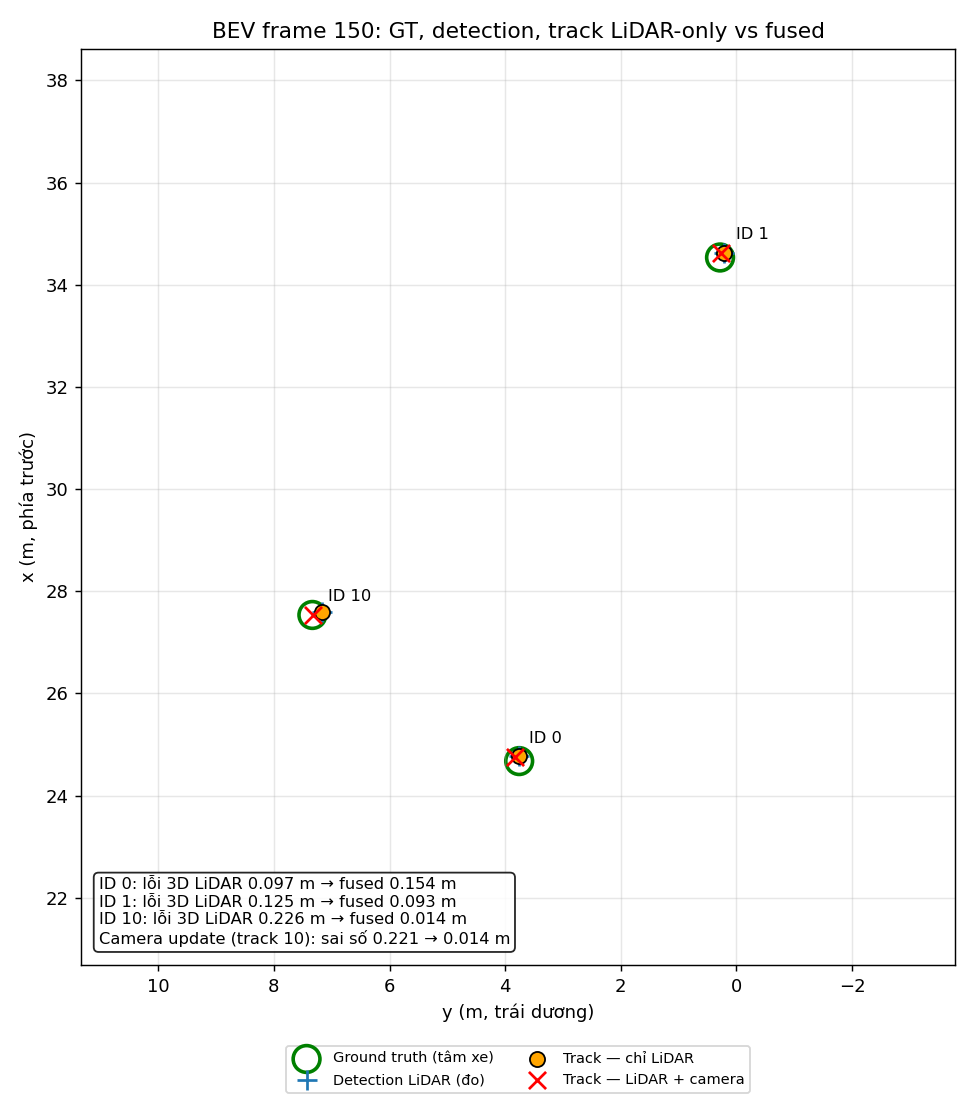

/tmp/repo/student/bonus/fig2_error_over_time.png


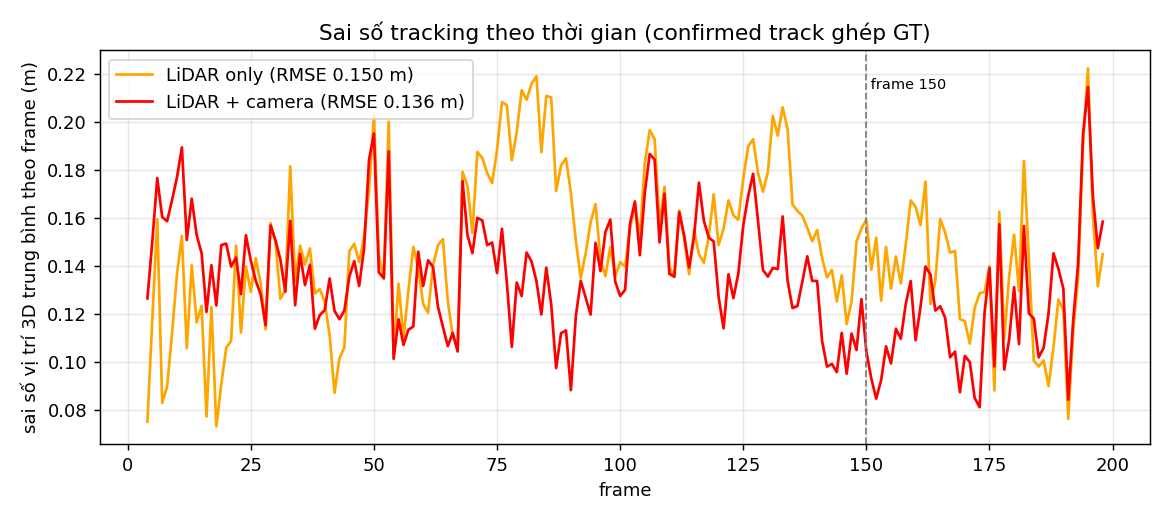

/tmp/repo/student/bonus/fig3_camera_overlay.png


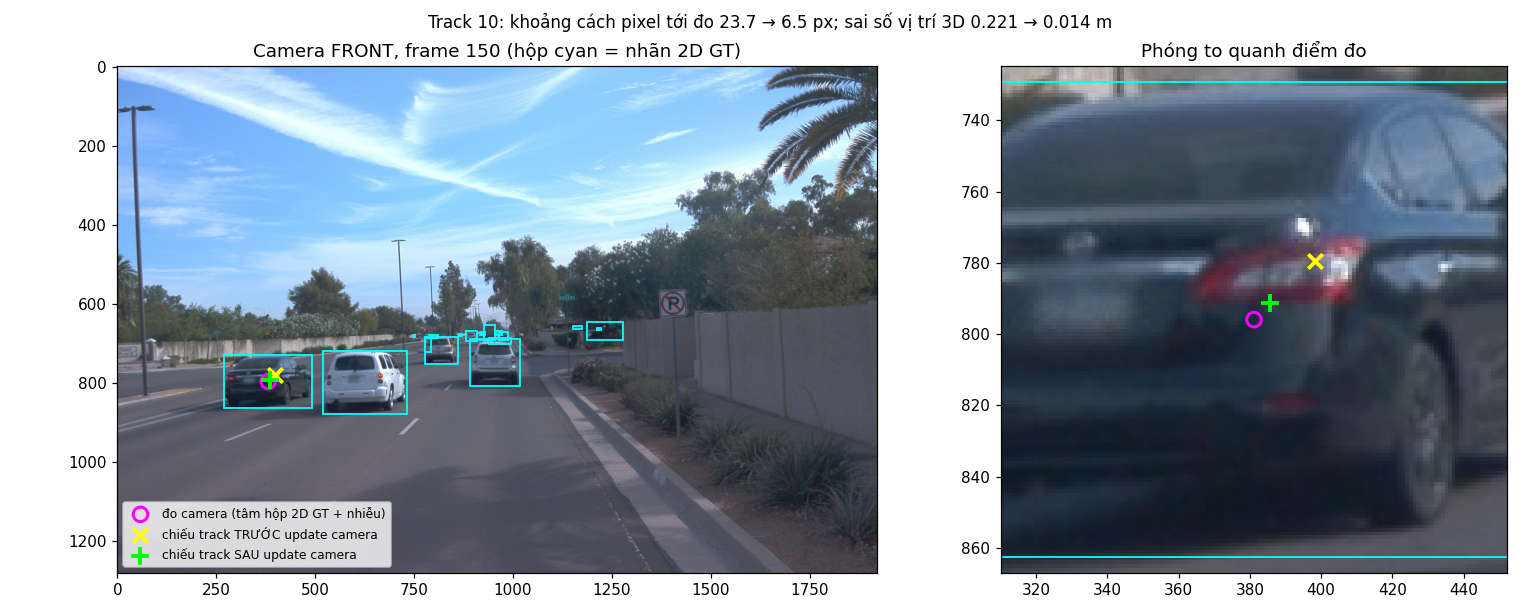

/tmp/repo/student/bonus/fig4_calibration_study.png


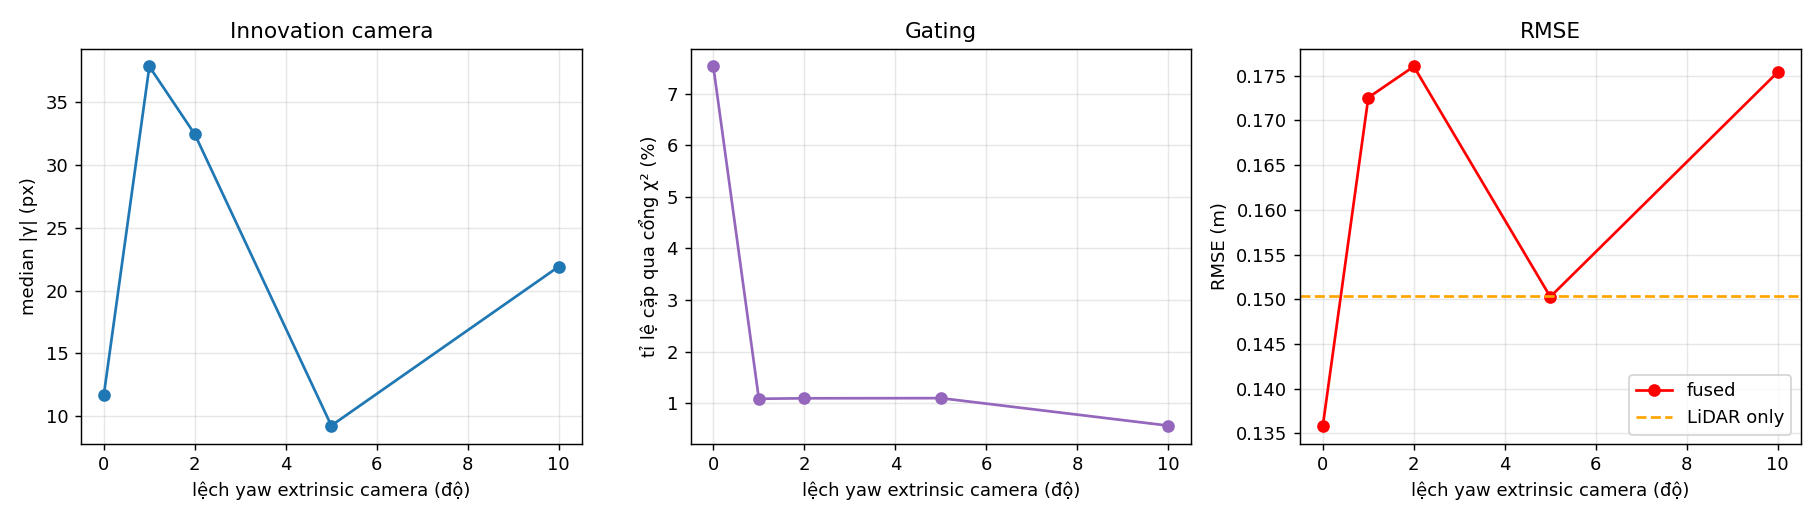

In [9]:
# Cell 7b — BONUS: lệch calibration + trực quan hoá (chỉ ĐỌC dữ liệu, không ghi đè student/artifacts)
!cd /tmp/repo && python student/bonus/run_bonus.py --config student/config/paths.yaml --seed 0 2>&1 | tail -60
import glob
from IPython.display import Image, display
for f in sorted(glob.glob(f"{REPO}/student/bonus/fig*.png")):
    print(f)
    display(Image(f))

In [10]:
# Cell 8 — tạo báo cáo SUBMISSION.md từ metrics.json VÀ đóng gói /kaggle/working/submission.zip (tab Output)
import json, pathlib

A = pathlib.Path(REPO) / "student" / "artifacts"
m = json.load(open(A / "metrics.json", encoding="utf-8"))
L, F, D = m["tracking"]["lidar"], m["tracking"]["fused"], m["detection"]

def fmt(v, nd=3):
    return "null" if v is None else f"{v:.{nd}f}"

def derived(t):
    prec = t["matches"] / (t["matches"] + t["ghost_track_frames"]) if (t["matches"] + t["ghost_track_frames"]) else 0.0
    cov = t["matches"] / D["tp"] if D["tp"] else 0.0
    return prec, cov

pL, cL = derived(L)
pF, cF = derived(F)
d_rmse = (F["rmse"] - L["rmse"]) if (F["rmse"] is not None and L["rmse"] is not None) else None

if d_rmse is None:
    verdict = "Không so sánh được RMSE vì một mode không có cặp ghép."
elif d_rmse < -0.005:
    verdict = f"Camera update làm RMSE giảm {abs(d_rmse):.3f} m so với chỉ LiDAR."
elif d_rmse > 0.005:
    verdict = f"Fused có RMSE cao hơn LiDAR {d_rmse:.3f} m."
else:
    verdict = "Hai mode có RMSE gần như tương đương."
ok_gate = (d_rmse is None) or (d_rmse <= 0.05)

summary = f"""- `fusion_mode`, `frames`, `segment`, `seed`: {m['fusion_mode']}, {m['frames']}, {m['segment']}, {m['seed']}
- `detection.precision`, `detection.recall`, `detection.tp/fp/fn`: {fmt(D['precision'])}, {fmt(D['recall'])}, {D['tp']}/{D['fp']}/{D['fn']}
- `tracking.lidar.rmse`, `matches`, `sum_sq_err`, `ghost_track_frames`, `missed_gt_frames`, `mean_confirmed_tracks`: {fmt(L['rmse'])} m, {L['matches']}, {fmt(L['sum_sq_err'])}, {L['ghost_track_frames']}, {L['missed_gt_frames']}, {fmt(L['mean_confirmed_tracks'])}
- `tracking.fused.rmse`, `matches`, `sum_sq_err`, `ghost_track_frames`, `missed_gt_frames`, `mean_confirmed_tracks`: {fmt(F['rmse'])} m, {F['matches']}, {fmt(F['sum_sq_err'])}, {F['ghost_track_frames']}, {F['missed_gt_frames']}, {fmt(F['mean_confirmed_tracks'])}
- Giải thích khác biệt hai mode, đọc RMSE cùng số ghép và ghost/miss: RMSE LiDAR = {fmt(L['rmse'])} m, fused = {fmt(F['rmse'])} m (fused − lidar = {fmt(d_rmse)} m; cổng ≤ 0.05 m: {'đạt' if ok_gate else 'KHÔNG đạt'}). {verdict} RMSE chỉ tính trên các cặp confirmed track–GT được ghép, nên phải đọc cùng số ghép: LiDAR có {L['matches']} cặp, fused có {F['matches']} cặp; ghost lần lượt {L['ghost_track_frames']} và {F['ghost_track_frames']}; miss lần lượt {L['missed_gt_frames']} và {F['missed_gt_frames']}. Với `precision_track = matches/(matches+ghost)` và `coverage = matches/det_tp` (det_tp = {D['tp']}): LiDAR {pL:.3f} / {cL:.3f}, fused {pF:.3f} / {cF:.3f} (ngưỡng đầy điểm 0.75 / 0.70). Số miss ({L['missed_gt_frames']}) chủ yếu do detector bỏ sót: detection.fn = {D['fn']}, phần còn lại {L['missed_gt_frames'] - D['fn']} là xe đã được detector phát hiện nhưng chưa có confirmed track ghép (trễ xác nhận vài frame đầu của mỗi track), nên không phải lỗi gán của tracker (coverage đã chỉ tính trên det_tp). Việc tạo, xác nhận và xoá track chỉ dựa vào LiDAR và detection dùng chung cho hai mode, nên số ghost/miss giữa hai mode gần như chỉ khác khi camera làm trạng thái EKF thay đổi (ví dụ vị trí track lệch ra ngoài hoặc vào cổng 2 m khi ghép GT). Giới hạn: đo camera là tâm hộp 2D ground-truth cộng nhiễu theo seed, không phải camera detector, nên kết quả fused không chứng minh chất lượng một perception độc lập."""


import numpy as np
B = pathlib.Path(REPO) / "student" / "bonus"
cal = json.load(open(B / "calibration_results.json", encoding="utf-8"))
bs = json.load(open(B / "bonus_summary.json", encoding="utf-8"))
table = (B / "calibration_table.md").read_text(encoding="utf-8")
lid = cal[0]
offs = [r for r in cal if r["yaw_deg"] is not None]
base, last = offs[0], offs[-1]
worst = max(offs, key=lambda r: r["rmse"] if r["rmse"] is not None else -1)
degraded = [r for r in offs if r["delta_vs_lidar"] is not None and r["delta_vs_lidar"] > 0.005]

def pct(v):
    return "n/a" if v is None else f"{100 * v:.1f}%"

yaws_txt = ", ".join(f"{r['yaw_deg']:g}°" for r in offs)
degraded_txt = ", ".join(f"{r['yaw_deg']:g}° (+{r['delta_vs_lidar']:.3f} m)" for r in degraded) or "không có mức nào"
over_gate = worst["delta_vs_lidar"] is not None and worst["delta_vs_lidar"] > 0.05
calib_text = (
    f"Xoay extrinsic camera FRONT quanh trục đứng với các mức lệch {yaws_txt} (0° là baseline, chạy lại cùng seed 0 trên cache detection dùng chung; "
    f"RMSE fused baseline {fmt(base['rmse'])} m so với {fmt(F['rmse'])} m ở lần chấm điểm). "
    f"Khi lệch tăng từ {base['yaw_deg']:g}° lên {last['yaw_deg']:g}°, median |γ| đổi từ {fmt(base['innovation_px_median'], 1)} px sang {fmt(last['innovation_px_median'], 1)} px, "
    f"tỉ lệ cặp qua cổng χ² từ {pct(base['gate_pass_rate'])} sang {pct(last['gate_pass_rate'])}, số lần update camera từ {base['camera_updates']} sang {last['camera_updates']}. "
    f"RMSE fused lớn nhất là {fmt(worst['rmse'])} m ở mức {worst['yaw_deg']:g}° (LiDAR {fmt(lid['rmse'])} m, chênh {fmt(worst['delta_vs_lidar'])} m; "
    f"{'vượt' if over_gate else 'không vượt'} ngưỡng 0.05 m của rubric). Các mức làm RMSE fused cao hơn LiDAR: {degraded_txt}. "
    "Giải thích cơ chế: lệch extrinsic làm h(x) chiếu sai nên innovation γ = z − h(x) có bias hệ thống tăng theo góc lệch; S không đổi nên d² = γᵀS⁻¹γ tăng, "
    "và khi d² vượt ngưỡng χ² (chi2.ppf(0.995, 2) ≈ 10.6) cặp bị cổng loại, camera gần như bị bỏ qua; các cặp còn lọt cổng mang bias nên kéo trạng thái EKF lệch "
    "(xem cột sai số trước → sau update). Lưu ý: tỉ lệ qua cổng tính trên mọi cặp track–đo trong FOV (kể cả cặp sai xe) nên ở 0° cũng không đạt 100%."
)
ev = bs.get("highlight_event")
if ev:
    d_pre = float(np.linalg.norm(np.array(ev["pre_px"]) - np.array(ev["meas_px"])))
    d_post = float(np.linalg.norm(np.array(ev["post_px"]) - np.array(ev["meas_px"])))
    ev_txt = (f"Ví dụ track {ev['track_id']} ở frame {ev['frame']}: sai số vị trí 3D so với GT giảm từ {ev['err_before']:.3f} m xuống {ev['err_after']:.3f} m sau một lần update camera; "
              f"khoảng cách pixel giữa điểm chiếu của track và đo camera giảm từ {d_pre:.1f} px xuống {d_post:.1f} px (fig1_bev_lidar_vs_fused.png, fig3_camera_overlay.png). "
              "Đây là lần update cải thiện nhiều nhất trong lần chạy (chọn để minh hoạ), không phải trường hợp điển hình. ")
else:
    ev_txt = "Không có lần update camera nào đủ điều kiện để minh hoạ. "
viz_text = (
    ev_txt + f"Trên {bs['baseline_camera_updates']} lần update camera (không lệch calibration) có GT ghép được, sai số vị trí trung bình đổi từ "
    f"{fmt(bs['camera_update_mean_err_before'])} m sang {fmt(bs['camera_update_mean_err_after'])} m, và {pct(bs['camera_update_share_improved'])} số lần giảm sai số. "
    f"Ảnh: {', '.join(bs['figures'])}."
)
cvat_text = ("Đã xuất track confirmed của chế độ fused ra `student/bonus/tracks_fused_cvat.json` bằng `fusion_lab.export_cvat.export_tracks_json`; "
             "chưa import vào CVAT và chưa chụp ảnh, nên không đề nghị tính điểm mục CVAT.")
bonus_md = "\n".join([
    "- **Phân tích lệch calibration (đề nghị +4).** " + calib_text, "", table,
    "- **Trực quan hoá track trên BEV và ảnh camera (đề nghị +3).** " + viz_text,
    "- **Export CVAT (không đề nghị điểm).** " + cvat_text, "",
    "Bằng chứng trong `student/bonus/`: `run_bonus.py`, `calibration_results.json`, `calibration_table.md`, `bonus_summary.json`, `tracks_fused_cvat.json` và các ảnh `fig*.png`.",
])
q4_note = f"Đã đo thực nghiệm ở phần Bonus bên dưới (lệch yaw {yaws_txt})."

report = f"""# Báo cáo bài nộp — Day 23 Sensor Fusion Lab

> Điền file này rồi commit. Cách nộp: [hướng dẫn nộp](../SUBMISSION.md).

## Thông tin học viên

- Họ tên: Nguyễn Thanh Hòa
- MSSV: 2A202602559
- Email: 26ai.hoant@vinuni.edu.vn
- Link repo (fork): https://github.com/Jikay-070203/K4-L2L3-DAY23-NguyenThanhHoa-2A202602559-SensorFusion
- Commit hash nộp (`git rev-parse HEAD`): nộp trên LMS (hash của commit cuối cùng chứa file này)

## Tóm tắt kết quả

{summary}

Chạy từ root repo:

```bash
fusion-run-lab --config student/config/paths.yaml --fusion compare --seed 0
```

`rmse = sqrt(sum_sq_err/matches)` trên vị trí 3D của confirmed tracks ghép
một-một với GT xe trong cửa sổ BEV, gate XY **2.0 m**; `null` nếu không có cặp.
Camera dùng tâm hộp 2D ground-truth FRONT có nhiễu seeded, **không** dùng camera
detector. Kết quả này không đo hiệu quả một perception system độc lập với GT.

`grade_run.log` là JSONL, mỗi `(mode,frame)` đúng một record với các trường:
`mode`, `frame`, `det_tp`, `det_fp`, `det_fn`, `valid_gt`, `confirmed`, `matches`,
`sum_sq_err`, `ghosts`, `misses`. Đảm bảo `matches+ghosts==confirmed` và
`matches+misses==valid_gt`; tổng/trung bình record phải khớp `metrics.json`.
File per-mode `metrics_lidar.json`, `metrics_fused.json`, `grade_run_lidar.log`,
`grade_run_fused.log` được giữ để đối chiếu.

## Giải thích ngắn (Parts E–H)

1. **Đo lidar 3D và camera 2D trong EKF.** Lidar: `z = (x, y, z)` tính bằng mét (tâm hộp 3D), `R = diag(0.1², 0.1², 0.1²)`, `h(x)` tuyến tính (đổi vị trí xe sang hệ cảm biến) nên `H` là ma trận 3×6 cố định (phần quay, cột vận tốc bằng 0). Camera: `z = (u, v)` tính bằng pixel, `R = diag(5², 5²)` px², `h(x)` là phép chiếu pinhole phi tuyến `u = c_i − f_i·y_s/x_s`, `v = c_j − f_j·z_s/x_s` nên `H` là Jacobian 2×6 (đạo hàm chiếu nhân ma trận quay) và phải tính lại quanh trạng thái hiện tại. Camera chỉ có 2 chiều nên không quan sát được độ sâu; lidar cho vị trí 3D trực tiếp (`kalman.py`, `camera_fusion.py`).
2. **Vì sao cần gating Mahalanobis trước khi gán.** Khoảng cách `d² = γᵀS⁻¹γ` với `S = HPHᵀ + R` chuẩn hoá sai số đo theo độ bất định của track và của cảm biến, nên khi `P` lớn thì chấp nhận đo xa hơn, khi `P` nhỏ thì khắt khe hơn, còn Euclid coi mọi hướng và mọi track như nhau. Cổng χ² (`chi2.ppf(0.995, dim_meas)`, dim 3 → 12.84, dim 2 → 10.60) loại các cặp phi lý trước khi greedy chọn cặp nhỏ nhất, tránh EKF bị kéo bởi đo của xe khác hoặc nhiễu (`association.py`: `chi2_gate`, `association_cost_matrix`).
3. **Track-then-fuse hay fuse-then-track.** Là **track-then-fuse**: chỉ một danh sách track; mỗi frame predict một lần, rồi gán + update LiDAR (AssocL), rồi gán + update camera (AssocC) trên cùng track; không trộn dữ liệu thô trước khi detect. Trên log `grade_run.log`, mỗi `(mode, frame)` có một record; các trường detection (`det_tp/fp/fn`, `valid_gt`) giống nhau giữa `lidar` và `fused` vì detector dùng chung, chỉ phần tracking (`confirmed`, `matches`, `ghosts`, `misses`, `sum_sq_err`) khác nhau — camera chỉ tinh chỉnh trạng thái track.
4. **Camera lệch calibration.** `h(x)` chiếu sai nên innovation `γ = z − h(x)` có sai số hệ thống (trung bình khác 0, lớn dần theo độ lệch và khoảng cách), `S` không đổi nên `d²` tăng. Nếu `d²` vượt cổng χ² thì cặp bị loại và camera không còn tác dụng; nếu chưa vượt, EKF bị kéo lệch nên vị trí track và RMSE xấu đi. {q4_note}
5. **Vì sao cần `sensor` tường minh ở frame rỗng; vai trò lidar vs camera.** Khi `meas_list` rỗng không còn `meas.sensor` để biết đây là lượt LiDAR hay camera, trong khi `manage_tracks` phải biết: lượt LiDAR rỗng vẫn phải trừ score các track nằm trong FOV (miss) và xoá track hết score, nếu không track ma sống mãi. Chỉ LiDAR quyết định score/khởi tạo/xoá; camera chỉ gọi `ekf_update` (không `update_track_score`, không tạo, không xoá), vì camera ở lab là hộp 2D ground-truth cộng nhiễu, chỉ 2 chiều, không phải detector độc lập, và để nó quyết định tồn tại sẽ làm track tồn tại nhờ nhãn (`manager.handle_updated_track`, `manage_tracks`).
6. **Xác nhận, giữ confirmed, xoá track.** Khởi tạo: `score = 1/window = 1/6`, `state = initialized`. Mỗi lần LiDAR hit cộng `1/6` (tối đa 1), miss trong FOV trừ `1/6`. `score > 0.8` thì `confirmed` (cần ít nhất 5 hit liên tiếp: 5/6 ≈ 0.833); chưa confirmed mà hit thì `tentative`; đã `confirmed` thì một miss không hạ trạng thái. Xoá khi `P[0,0]` hoặc `P[1,1] > max_P = 9`, hoặc confirmed có `score < 0.6` (từ 1.0 cần 3 miss liên tiếp: 0.5), hoặc chưa confirmed có `score <= 0` (`track_management.py: should_delete_track`).

## Bonus (không bắt buộc)

{bonus_md}

## Khai báo sử dụng AI (bắt buộc)

- Công cụ đã dùng (ChatGPT, Copilot, Claude, …): Claude (Claude Code, Anthropic)
- Dùng cho phần nào (hàm, câu hỏi, debug): viết code Part E–H (`kalman.py`, `association.py`, `camera_fusion.py`, `track_management.py`), tạo notebook chạy Kaggle, viết script bonus `student/bonus/run_bonus.py` (thí nghiệm lệch calibration, trực quan hoá, xuất track), và soạn nháp báo cáo này (phần số liệu được sinh tự động từ `metrics.json`).
- Cách bạn đã kiểm tra lại (pytest, chạy Waymo, đối chiếu công thức): chạy `pytest student/tests` (toàn bộ pass), chạy `fusion-run-lab --fusion compare --seed 0` trên toàn segment và dùng `metrics.json`/`grade_run.log` sinh ra, đối chiếu công thức EKF/Mahalanobis/pinhole với tài liệu và test.

## Checklist nộp

- [ ] **Part E–H** trong `workspace/` đã implement; `pytest student/tests -q` không còn `failed`/`xfailed`
- [ ] Part A–D: không bắt buộc sửa (hoặc ghi chú nếu bạn đã sửa)
- [ ] Lần chạy chấm điểm: `--fusion compare --seed 0`, `frame_start: 0`, `frame_end: 198`
- [ ] Đã commit `student/artifacts/metrics*.json` và `student/artifacts/grade_run*.log` (không sửa tay)
- [ ] Đã điền đủ file này, gồm khai báo AI
- [ ] Không commit dữ liệu Waymo, weights, `paths.yaml`, API key
- [ ] `python tools/check_submission.py` báo `KẾT QUẢ: SẴN SÀNG NỘP`
- [ ] Đã push và nộp link repo + commit hash trên LMS ([hướng dẫn nộp](../SUBMISSION.md))
"""
(pathlib.Path(REPO) / "student" / "SUBMISSION.md").write_text(report, encoding="utf-8")
print(report[:1500])

# ---- gom kết quả vào /kaggle/working để tải về (tab Output) ----
import shutil, pathlib
OUT = pathlib.Path("/kaggle/working/submission")
if OUT.exists(): shutil.rmtree(OUT)
(OUT / "student" / "artifacts").mkdir(parents=True)
(OUT / "student" / "workspace").mkdir(parents=True)
for f in ["metrics.json", "grade_run.log", "metrics_lidar.json", "metrics_fused.json",
          "grade_run_lidar.log", "grade_run_fused.log"]:
    shutil.copy(A / f, OUT / "student" / "artifacts" / f)
shutil.copy(f"{REPO}/student/SUBMISSION.md", OUT / "student" / "SUBMISSION.md")
for f in ["kalman.py", "association.py", "camera_fusion.py", "track_management.py"]:
    shutil.copy(f"{REPO}/student/workspace/{f}", OUT / "student" / "workspace" / f)
shutil.copytree(f"{REPO}/student/bonus", OUT / "student" / "bonus")
shutil.make_archive("/kaggle/working/submission", "zip", OUT)
print(sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file()))
print("-> Tải /kaggle/working/submission.zip (tab Output), giải nén ĐÈ vào gốc repo trên máy bạn.")

# Báo cáo bài nộp — Day 23 Sensor Fusion Lab

> Điền file này rồi commit. Cách nộp: [hướng dẫn nộp](../SUBMISSION.md).

## Thông tin học viên

- Họ tên: Nguyễn Thanh Hòa
- MSSV: 2A202602559
- Email: 26ai.hoant@vinuni.edu.vn
- Link repo (fork): https://github.com/Jikay-070203/K4-L2L3-DAY23-NguyenThanhHoa-2A202602559-SensorFusion
- Commit hash nộp (`git rev-parse HEAD`): nộp trên LMS (hash của commit cuối cùng chứa file này)

## Tóm tắt kết quả

- `fusion_mode`, `frames`, `segment`, `seed`: compare, [0, 198], training_segment-1005081002024129653_5313_150_5333_150_with_camera_labels.tfrecord, 0
- `detection.precision`, `detection.recall`, `detection.tp/fp/fn`: 0.970, 0.700, 519/16/222
- `tracking.lidar.rmse`, `matches`, `sum_sq_err`, `ghost_track_frames`, `missed_gt_frames`, `mean_confirmed_tracks`: 0.150 m, 502, 11.344, 0, 239, 2.523
- `tracking.fused.rmse`, `matches`, `sum_sq_err`, `ghost_track_frames`, `missed_gt_frames`, `mean_confirmed_tracks`: 0.136 m, 502, 9.267, 0, 239, 2.523
- Gi